# Dark Store Performance Analysis
**Question:** Why do some of our 12 Bengaluru dark stores miss the 10-minute delivery promise far more often than others, what is it costing us, and what should operations do about it?

This notebook walks through the analysis step by step. The heavy lifting lives in SQL (`sql/`) and `src/`; here we query the cleaned DuckDB warehouse and read the results.

> **Data note:** real dark-store data is not public, so the data is generated by `src/generate_data.py`, an operational simulation where delivery time = picking + rider wait + travel. See the README for how it works.

In [1]:
import json, sys
from pathlib import Path
import duckdb, pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(ROOT / "data" / "darkstore.duckdb"), read_only=True)
P = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
m = json.loads((ROOT / "reports" / "metrics.json").read_text())
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
q = lambda sql: con.execute(sql).df()

## 1. Data and cleaning
The raw export has the usual problems. `sql/00_staging.sql` fixes them and logs what it changed:

In [2]:
q("SELECT * FROM data_quality_log")

,check_name,rows_affected
0,Duplicate order rows removed,459
1,Store IDs with bad casing/whitespace fixed,690
2,Payment method labels standardised,912
3,Delivered orders with impossible timings (excl...,70
4,Missing distances imputed from coordinates,343
5,"Orders not rated by customer (expected, left a...",50054


In [3]:
q("SELECT table_name, estimated_size AS rows FROM duckdb_tables() WHERE table_name LIKE 'dim_%' OR table_name LIKE 'fact_%' ORDER BY 1")

,table_name,rows
0,dim_customer,25000
1,dim_date,181
2,dim_product,60
3,dim_store,12
4,dim_weather_hour,4344
5,fact_order_items,396329
6,fact_orders,114652
7,fact_rider_shifts,52128


## 2. Network health
Monthly KPIs (`sql/01_network_kpis_monthly.sql`). Volume grows every month, but so does the late rate - from about 1 in 5 orders in January to 1 in 3 in June.

In [4]:
pd.read_csv(P / "network_kpis_monthly.csv")

,month,orders,active_customers,gmv_inr,aov_inr,avg_delivery_min,p90_delivery_min,late_pct,cancel_pct,orders_with_missing_items_pct,avg_rating
0,2026-01-01,17895,8389,5450911.0,314.4,11.18,17.93,22.5,3.13,7.7,4.32
1,2026-02-01,15822,8016,4784621.0,312.8,10.89,17.10,20.9,3.31,7.5,4.35
2,2026-03-01,18860,9028,5737315.0,314.7,11.00,17.34,22.3,3.32,7.6,4.33
3,2026-04-01,19107,9545,5705777.0,308.9,11.01,17.43,24.0,3.32,9.3,4.29
4,2026-05-01,21380,10498,6335500.0,308.8,11.44,18.13,27.2,4.05,9.5,4.23
5,2026-06-01,21588,10772,6468626.0,311.7,12.12,19.59,33.6,3.85,8.0,4.13


## 3. Which stores are struggling?
`sql/02_store_scorecard.sql`

In [5]:
pd.read_csv(P / "store_scorecard.csv")[["store_id","store_name","orders_per_day","avg_delivery_min","p90_delivery_min","late_pct","cancel_pct","avg_rating","avg_distance_km","far_orders_pct","avg_rider_utilization"]]

,store_id,store_name,orders_per_day,avg_delivery_min,p90_delivery_min,late_pct,cancel_pct,avg_rating,avg_distance_km,far_orders_pct,avg_rider_utilization
0,S10,DS Electronic City,37.6,12.72,19.50,43.2,3.80,4.01,2.00,25.6,0.81
1,S07,DS Whitefield,48.2,14.07,22.48,39.6,4.99,4.01,2.57,41.9,1.17
2,S04,DS Bellandur,75.0,13.14,21.33,28.8,2.48,4.22,2.99,43.7,0.73
3,S12,DS Yelahanka,28.0,11.92,19.74,28.3,4.04,4.22,2.22,28.0,0.93
4,S03,DS HSR Layout,64.9,11.24,18.77,28.0,4.14,4.19,1.82,8.1,0.99
5,S11,DS Hebbal,38.5,11.29,18.00,26.7,3.66,4.26,1.97,16.4,0.93
6,S08,DS Marathahalli,39.8,10.46,15.81,22.5,4.11,4.30,1.74,11.7,0.91
7,S09,DS Malleshwaram,44.2,10.65,15.63,22.2,3.78,4.34,1.90,13.4,0.88
8,S06,DS BTM Layout,55.7,10.18,16.90,21.6,3.24,4.34,1.76,14.6,0.86
9,S02,DS Indiranagar,63.5,10.39,14.88,20.5,3.19,4.35,1.85,11.1,0.85


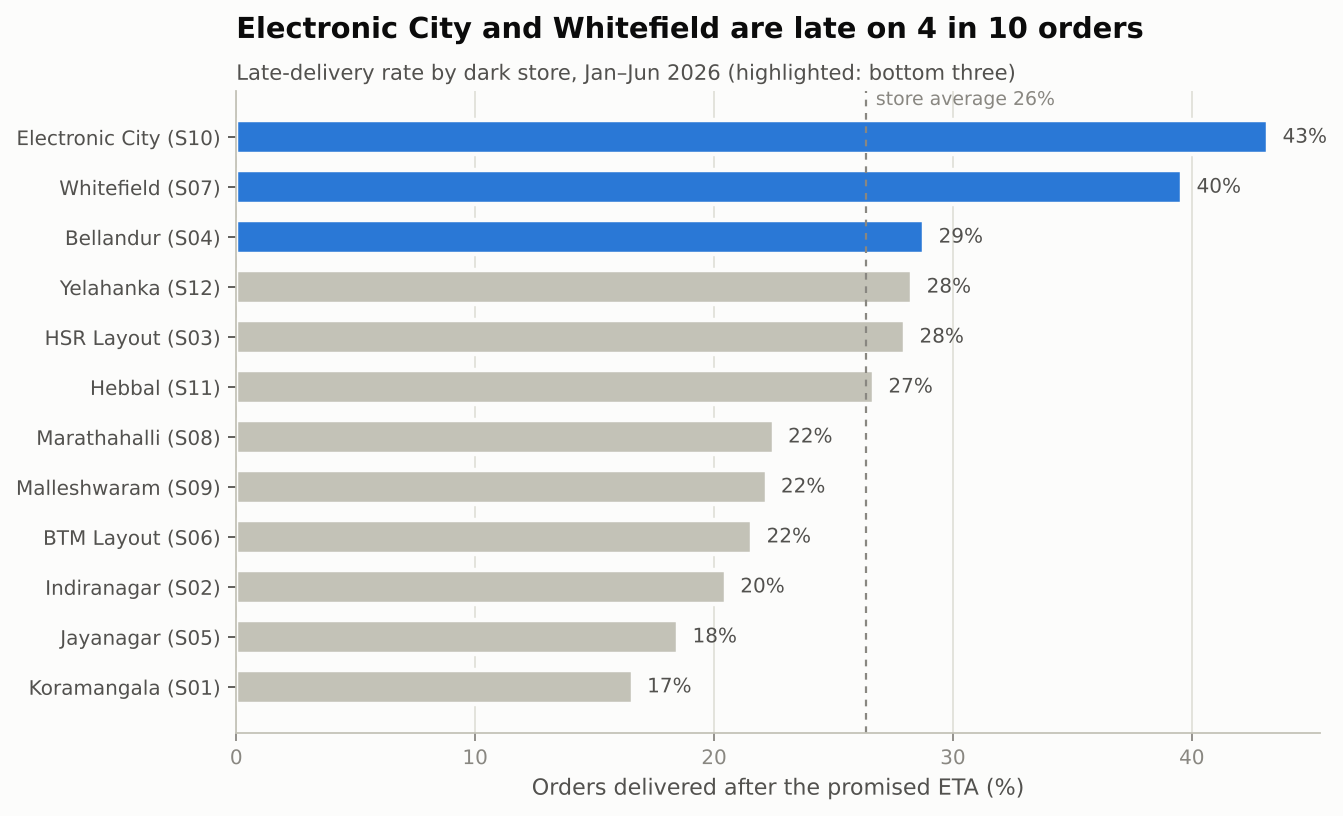

In [6]:
Image(FIG / "01_store_late_rate.png", width=750)

## 4. Diagnose: where does each store lose time?
Every delivery is three stages - **picking** inside the store, **waiting** for a free rider, and **travel**. Comparing each stage with the network average names the bottleneck (`sql/03_delivery_time_breakdown.sql`):

In [7]:
pd.read_csv(P / "delivery_time_breakdown.csv")

,store_id,pick_min,rider_wait_min,travel_min,delivery_min,pick_gap_vs_network,wait_gap_vs_network,travel_gap_vs_network,primary_bottleneck
0,S07,2.73,3.27,8.08,14.07,-0.14,1.48,1.43,Rider shortage (orders wait for riders)
1,S04,2.75,1.09,9.30,13.14,-0.12,-0.70,2.65,Long distances (catchment too wide)
2,S10,4.73,1.52,6.46,12.72,1.87,-0.26,-0.19,Slow picking (in-store)
3,S12,2.77,2.08,7.07,11.92,-0.10,0.30,0.41,On par with network
4,S11,2.77,2.14,6.38,11.29,-0.10,0.36,-0.27,On par with network
5,S03,2.76,2.52,5.97,11.24,-0.11,0.73,-0.69,Rider shortage (orders wait for riders)
6,S05,2.73,1.35,6.80,10.87,-0.14,-0.43,0.15,On par with network
7,S09,2.77,1.74,6.15,10.65,-0.10,-0.05,-0.50,On par with network
8,S08,2.73,1.99,5.74,10.46,-0.14,0.21,-0.91,On par with network
9,S02,2.77,1.58,6.04,10.39,-0.10,-0.21,-0.61,On par with network


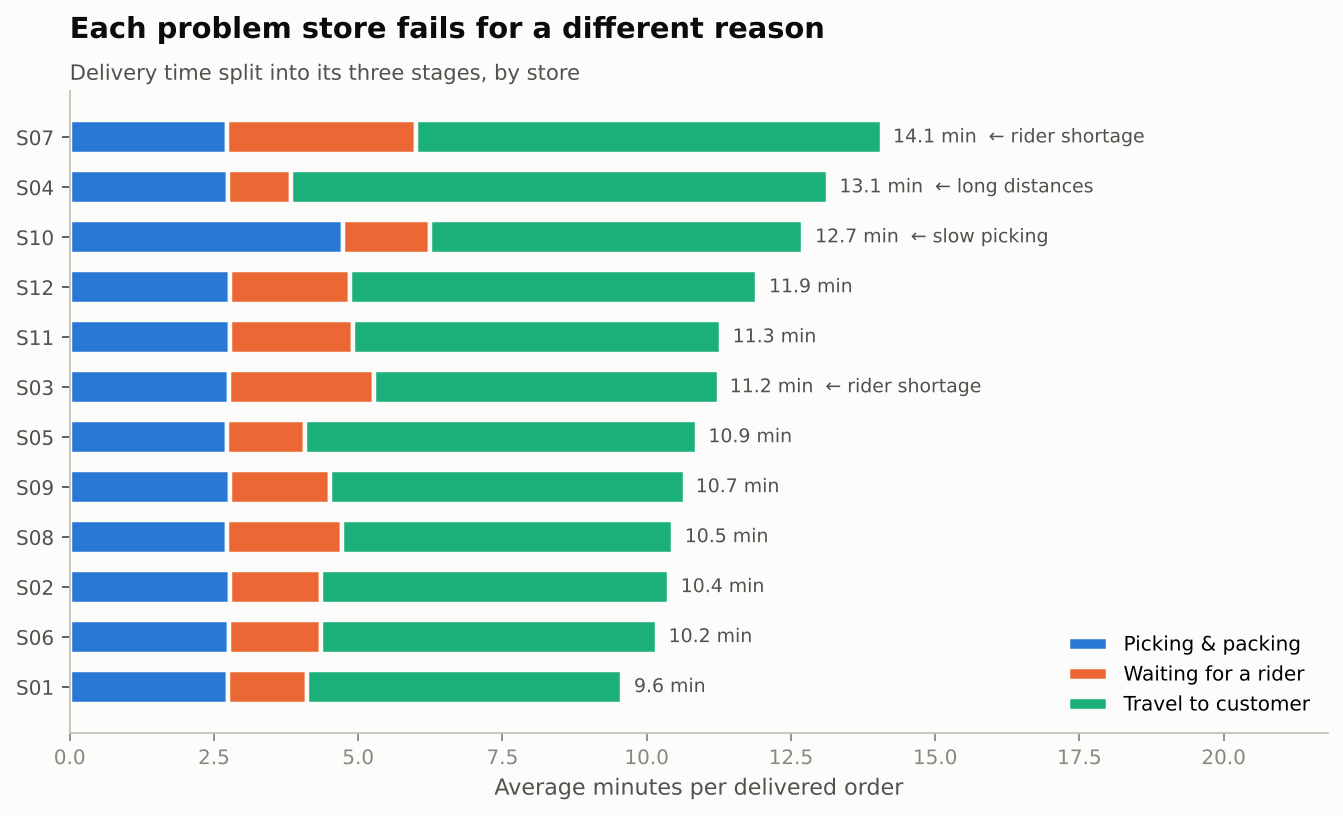

In [8]:
Image(FIG / "02_delivery_time_breakdown.png", width=750)

Three stores, three different problems:
- **Whitefield (S07)** - orders wait ~3.3 min for a rider vs ~1.8 network: *understaffed*.
- **Bellandur (S04)** - travel is 9.3 min vs 6.6: it serves far-away neighbourhoods (*catchment too wide*).
- **Electronic City (S10)** - picking takes 4.7 min vs 2.9 network average: *slow in-store operations*.

## 5. What drives lateness overall?
`sql/04_late_drivers.sql`

In [9]:
pd.read_csv(P / "late_drivers.csv")

,driver,level,orders,late_pct,avg_delivery_min
0,Distance,0-1 km,22787,12.4,7.52
1,Distance,1-2 km,41926,20.9,9.62
2,Distance,2-3 km,23674,28.6,12.33
3,Distance,3-4 km,12051,31.2,15.24
4,Distance,4+ km,10101,59.5,19.74
5,Rider utilisation,1. <60%,32680,12.7,10.06
6,Rider utilisation,2. 60-90%,27048,14.9,10.34
7,Rider utilisation,3. 90-120%,30063,20.4,10.74
8,Rider utilisation,4. >120%,20748,66.6,15.34
9,Time of day,1. Morning (6-11),25264,29.7,11.79


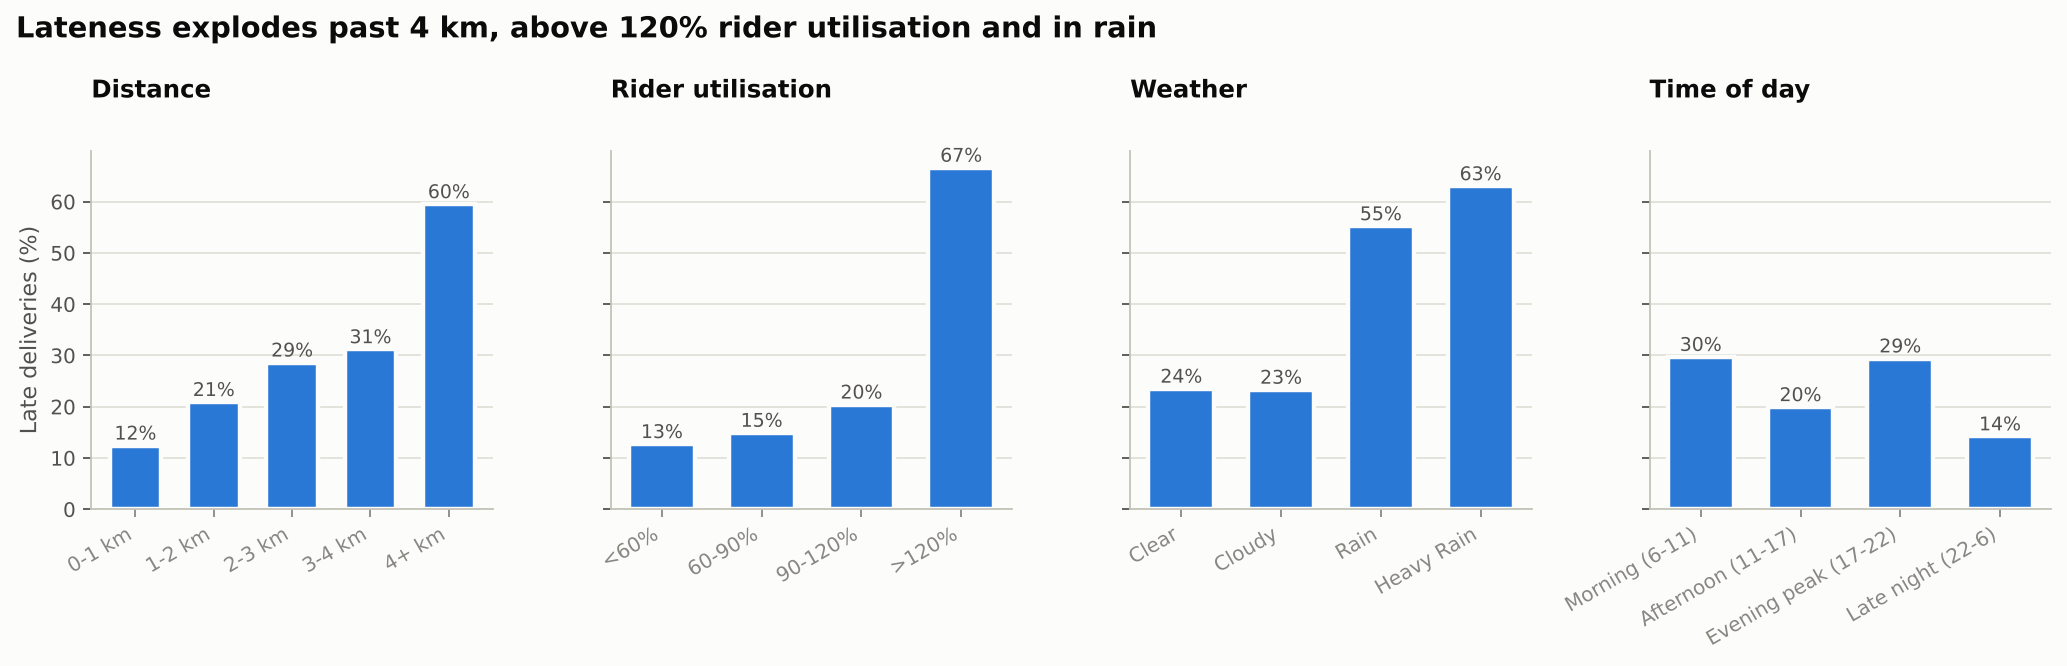

In [10]:
Image(FIG / "03_late_rate_drivers.png", width=950)

### Regression: separating the effects
Distance, weather, traffic and rider load overlap (e.g. rain hits during evening peaks). An OLS model with store fixed effects isolates each one's contribution:

In [11]:
coef = pd.read_csv(P / "delivery_time_drivers_model.csv")
print(f"R² = {m['model_r2']}")
coef[~coef.driver.str.startswith("Store effect") | (coef.minutes_added.abs() > 0.5)]

R² = 0.833


,driver,minutes_added,ci_low,ci_high,p_value
0,Each extra km of distance,2.84,2.83,2.86,0.000000e+00
1,Rain (vs clear),1.82,1.72,1.92,1.800000e-281
2,Heavy rain (vs clear),2.70,2.58,2.82,0.000000e+00
3,Peak traffic hour,1.78,1.76,1.81,0.000000e+00
4,Each +10 pts rider utilisation above 75%,0.68,0.67,0.69,0.000000e+00
5,Each extra item in the basket,0.40,0.39,0.41,0.000000e+00
6,Weekend,-0.05,-0.08,-0.03,7.500000e-05
15,"Store effect S10 (vs Koramangala, all else equal)",2.02,1.96,2.08,0.000000e+00


After controlling for distance, weather, traffic and rider utilisation, **every store behaves the same except Electronic City (+2 min)**. That confirms its problem is inside the store, not outside it.

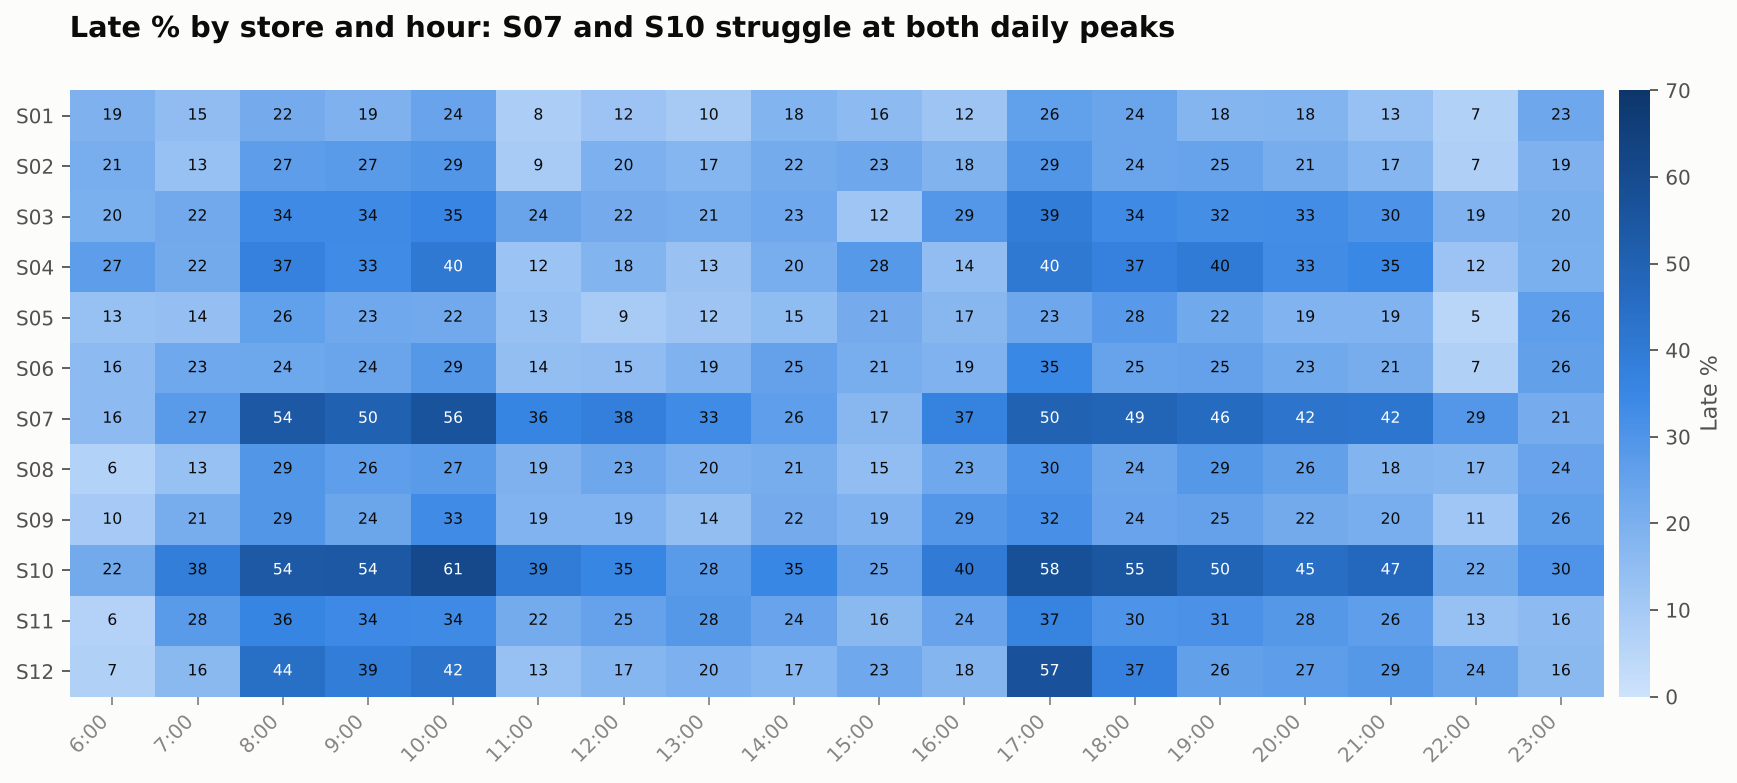

In [12]:
Image(FIG / "04_store_hour_heatmap.png", width=950)

## 6. Catching problems early: the HSR Layout incident
A weekly monitor flags any store whose late rate jumps more than 3 standard deviations above its own 8-week baseline **and** 10+ points beyond the city-wide trend (so rainy weeks don't cause false alarms).

In [13]:
pd.read_csv(P / "incident_alerts.csv")[["store_id","week_start","late_pct","baseline_late_pct","jump_vs_network_pts","avg_rider_wait_min","avg_riders_on_shift"]]

,store_id,week_start,late_pct,baseline_late_pct,jump_vs_network_pts,avg_rider_wait_min,avg_riders_on_shift
0,S03,2026-05-18,59.5,18.90,35.51,5.96,1.55
1,S12,2026-03-09,32.4,22.82,10.33,2.78,1.52


In [14]:
pd.Series(m["incident"])

store_id                         S03
week_detected             2026-05-18
late_pct_before                 19.0
late_pct_after                  60.9
rider_wait_min_before           1.46
rider_wait_min_after            6.44
riders_on_shift_before          3.22
riders_on_shift_after           1.58
delivery_min_before             9.94
delivery_min_after             15.33
dtype: object

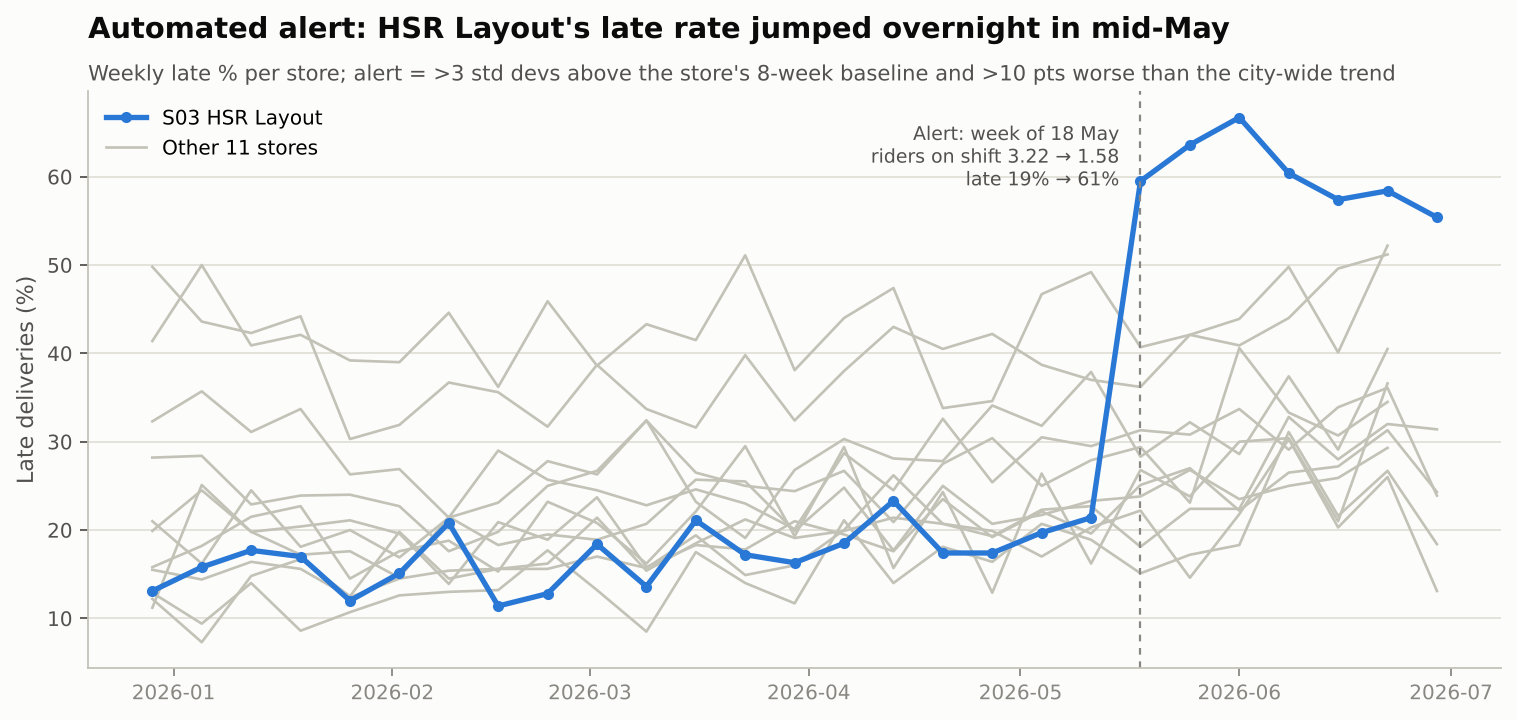

In [15]:
Image(FIG / "05_incident_detection.png", width=900)

Riders on shift halved from the week of 18 May. Picking and travel didn't change - only rider wait did. Root cause: rider attrition.

## 7. What lateness costs
### Customers who get a late first order come back less
`sql/08_retention_first_order.sql`

In [16]:
pd.read_csv(P / "retention_first_order.csv")

,first_order_experience,customers,repeat_within_30d_pct,avg_orders_next_30d
0,On time,4670,69.7,1.61
1,Late by < 5 min,1164,62.6,1.42
2,Late by 5+ min,372,53.0,1.06
3,Cancelled,231,61.0,1.34


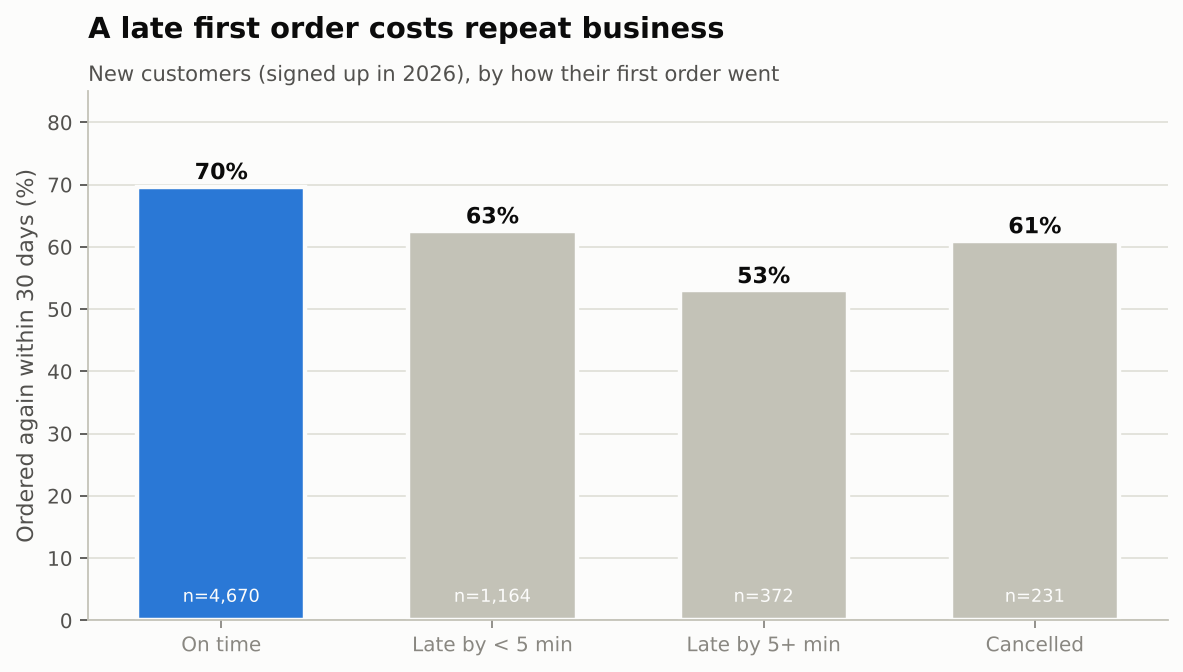

In [17]:
Image(FIG / "06_retention_after_first_order.png", width=650)

### Ratings collapse as soon as an order is late
`sql/10_rating_vs_lateness.sql`

In [18]:
pd.read_csv(P / "rating_vs_lateness.csv")

,lateness,has_missing_items,rated_orders,avg_rating,bad_rating_pct
0,1. On time,False,41389,4.71,0.0
1,1. On time,True,3735,3.90,0.2
2,2. Late 0-3 min,False,8666,3.41,2.4
3,2. Late 0-3 min,True,801,2.59,41.3
4,3. Late 3-6 min,False,2910,3.19,5.8
5,3. Late 3-6 min,True,269,2.36,62.5
6,4. Late 6-10 min,False,1448,2.97,15.7
7,4. Late 6-10 min,True,140,2.09,78.6
8,5. Late 10+ min,False,1061,2.49,51.6
9,5. Late 10+ min,True,101,1.70,94.1


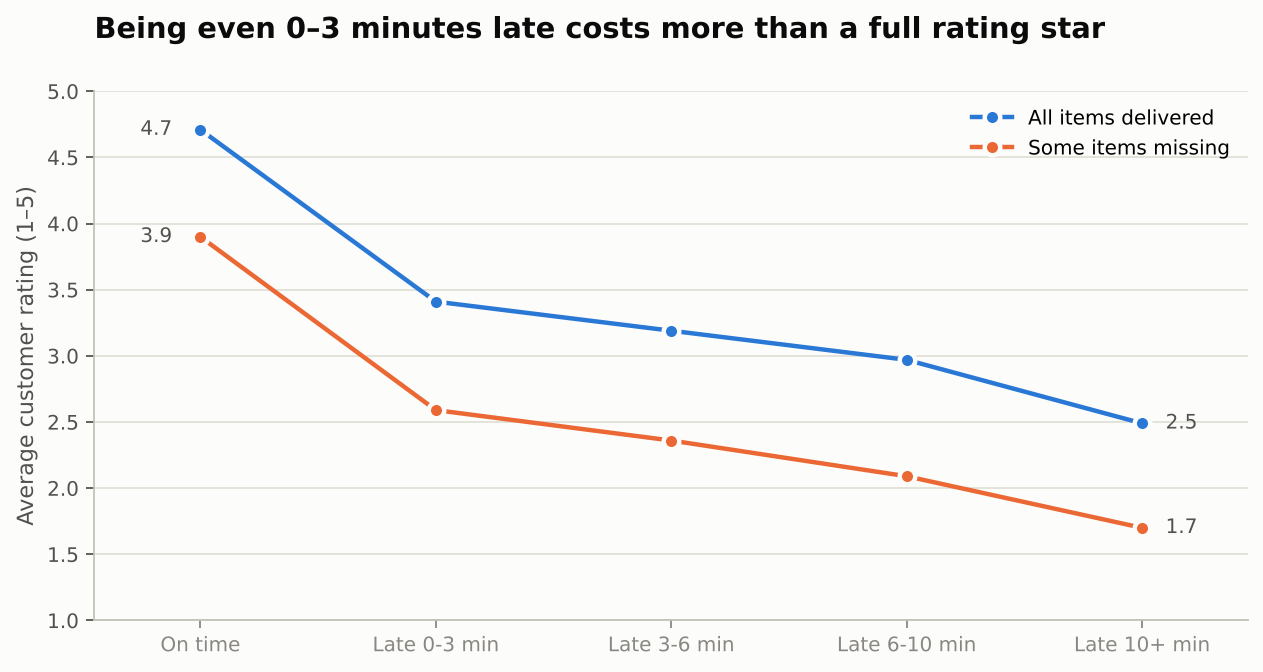

In [19]:
Image(FIG / "07_rating_vs_lateness.png", width=700)

In [20]:
pd.Series(m["revenue_impact"])

aov_inr                                       311.80
repeat_30d_on_time_pct                         69.70
repeat_30d_late_pct                            60.30
repeat_gap_pp                                   9.40
orders_lost_per_late_first_order_30d            0.28
gmv_lost_per_1000_late_first_orders_inr     86414.00
stockout_lost_revenue_6m_inr               862237.00
stockout_lost_revenue_per_month_inr        143706.00
icecream_s05_s10_lost_inr                   75025.00
slow_delivery_cancellations_6m               1859.00
slow_delivery_cancel_gmv_6m_inr            579365.00
dtype: float64

## 8. Stockouts and basket patterns
`sql/07_stockouts.sql`

In [21]:
so = pd.read_csv(P / "stockouts.csv")
so.groupby("category").lost_revenue_inr.sum().sort_values(ascending=False)

category
Ice Cream & Frozen     173345.0
Dairy & Bread          120354.0
Staples                116765.0
Fruits & Vegetables    108525.0
Personal Care           66124.0
Beverages               60655.0
Snacks                  55630.0
Household               53231.0
Instant Food            52585.0
Baby Care               49125.0
Health & OTC             5898.0
Name: lost_revenue_inr, dtype: float64

In [22]:
so.head(10)

,store_id,sku_id,product_name,category,times_requested,times_unavailable,stockout_pct,lost_revenue_inr
0,S05,P037,Vanilla Ice Cream Tub 700ml,Ice Cream & Frozen,1065,186.0,17.5,41940.0
1,S10,P037,Vanilla Ice Cream Tub 700ml,Ice Cream & Frozen,629,85.0,13.5,18540.0
2,S04,P037,Vanilla Ice Cream Tub 700ml,Ice Cream & Frozen,1233,46.0,3.7,10800.0
3,S01,P037,Vanilla Ice Cream Tub 700ml,Ice Cream & Frozen,1153,45.0,3.9,9900.0
4,S03,P037,Vanilla Ice Cream Tub 700ml,Ice Cream & Frozen,1061,45.0,4.2,9900.0
5,S02,P037,Vanilla Ice Cream Tub 700ml,Ice Cream & Frozen,1086,39.0,3.6,9180.0
6,S04,P057,Diapers Medium (20 pcs),Baby Care,488,15.0,3.1,7581.0
7,S07,P037,Vanilla Ice Cream Tub 700ml,Ice Cream & Frozen,763,29.0,3.8,7560.0
8,S05,P038,Chocolate Ice Cream Cone,Ice Cream & Frozen,795,121.0,15.2,7245.0
9,S06,P037,Vanilla Ice Cream Tub 700ml,Ice Cream & Frozen,912,30.0,3.3,7020.0


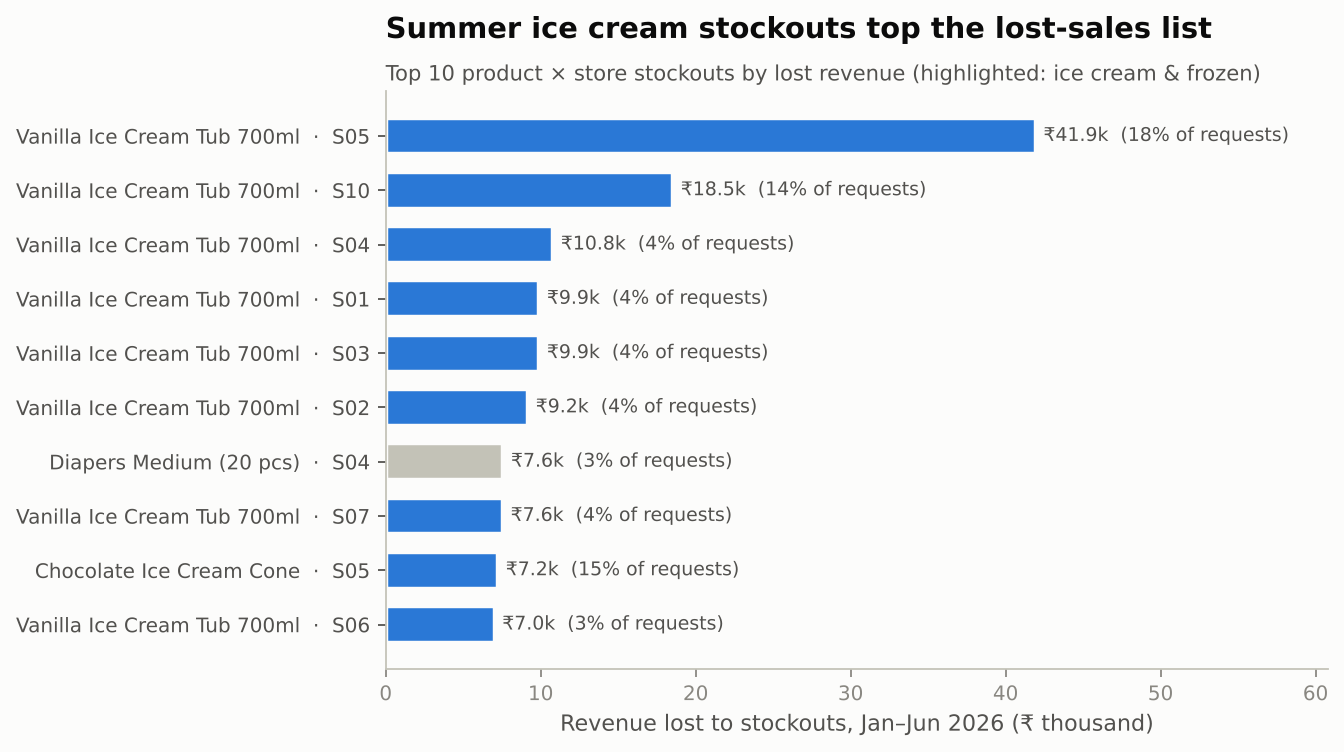

In [23]:
Image(FIG / "08_stockout_lost_revenue.png", width=750)

Market basket analysis (FP-Growth on ~110k delivered baskets) finds bundle and 'frequently bought together' candidates:

In [24]:
pd.read_csv(P / "basket_rules.csv").head(12)

,if_customer_buys,they_also_buy,support,confidence,lift,orders_with_both
0,Baby Wipes (72 pcs),Diapers Medium (20 pcs),0.015,0.532,14.545,1659
1,Cup Noodles + Frozen Paratha (5 pcs),Instant Noodles Masala (4 pack),0.010,0.770,7.392,1106
2,Dishwash Bar (3 pcs),Liquid Detergent 1L,0.010,0.291,7.347,1106
3,Cup Noodles + Tomato Ketchup 500g,Instant Noodles Masala (4 pack),0.009,0.746,7.160,995
4,Chocolate Ice Cream Cone + Kulfi Stick,Vanilla Ice Cream Tub 700ml,0.012,0.592,6.600,1327
5,Kulfi Stick,Chocolate Ice Cream Cone,0.020,0.416,6.436,2212
6,Apple Shimla (4 pcs),Banana (6 pcs),0.014,0.438,6.394,1549
7,Cup Noodles,Instant Noodles Masala (4 pack),0.031,0.640,6.143,3429
8,Green Chilli 100g + Potato 1kg,Tomato 1kg,0.010,0.762,6.038,1106
9,Green Chilli 100g + Paneer 200g,Tomato 1kg,0.010,0.753,5.971,1106


## 9. Where should the next store open?
Orders delivered more than 3.5 km away are clustered with K-means. For each cluster centre, we simulate opening a store there: every order closer to the new site is re-routed, travel time is scaled by the new distance, and the app's ETA tiers are re-applied.

In [25]:
pd.read_csv(P / "expansion_candidates.csv")

,candidate_site_near,lat,lon,currently_served_by,orders_reassigned_6m,orders_reassigned_per_day,gmv_reassigned_6m_inr,avg_distance_now_km,avg_distance_new_km,late_pct_now,late_pct_new,avg_delivery_now,avg_delivery_new,network_late_pct_now,network_late_pct_new
0,Carmelaram,12.9084,77.7034,S04,5578,30.8,1739479,4.78,1.46,49.7,12.7,18.27,8.82,25.44,23.58
1,Begur,12.8923,77.6046,S06,2201,12.2,682590,4.91,3.28,57.2,30.3,19.37,14.73,25.44,24.90
2,Jakkur,13.0701,77.6038,S12,1874,10.4,590657,4.49,1.17,48.5,21.1,18.31,8.91,25.44,24.97
3,Domlur,12.9544,77.6414,S02,3784,20.9,1171530,2.93,1.46,26.3,16.7,13.36,9.21,25.44,25.11
4,Electronic City Ph 2,12.8329,77.6835,S10,2022,11.2,635654,3.61,1.22,54.2,39.2,17.33,10.54,25.44,25.16
5,Varthur,12.9605,77.7384,S07,2952,16.3,918910,3.90,2.79,48.6,39.5,17.79,14.65,25.44,25.20
6,Basavanagudi,12.9766,77.5658,S09,967,5.3,307632,3.32,2.29,30.0,25.9,14.77,11.87,25.44,25.40


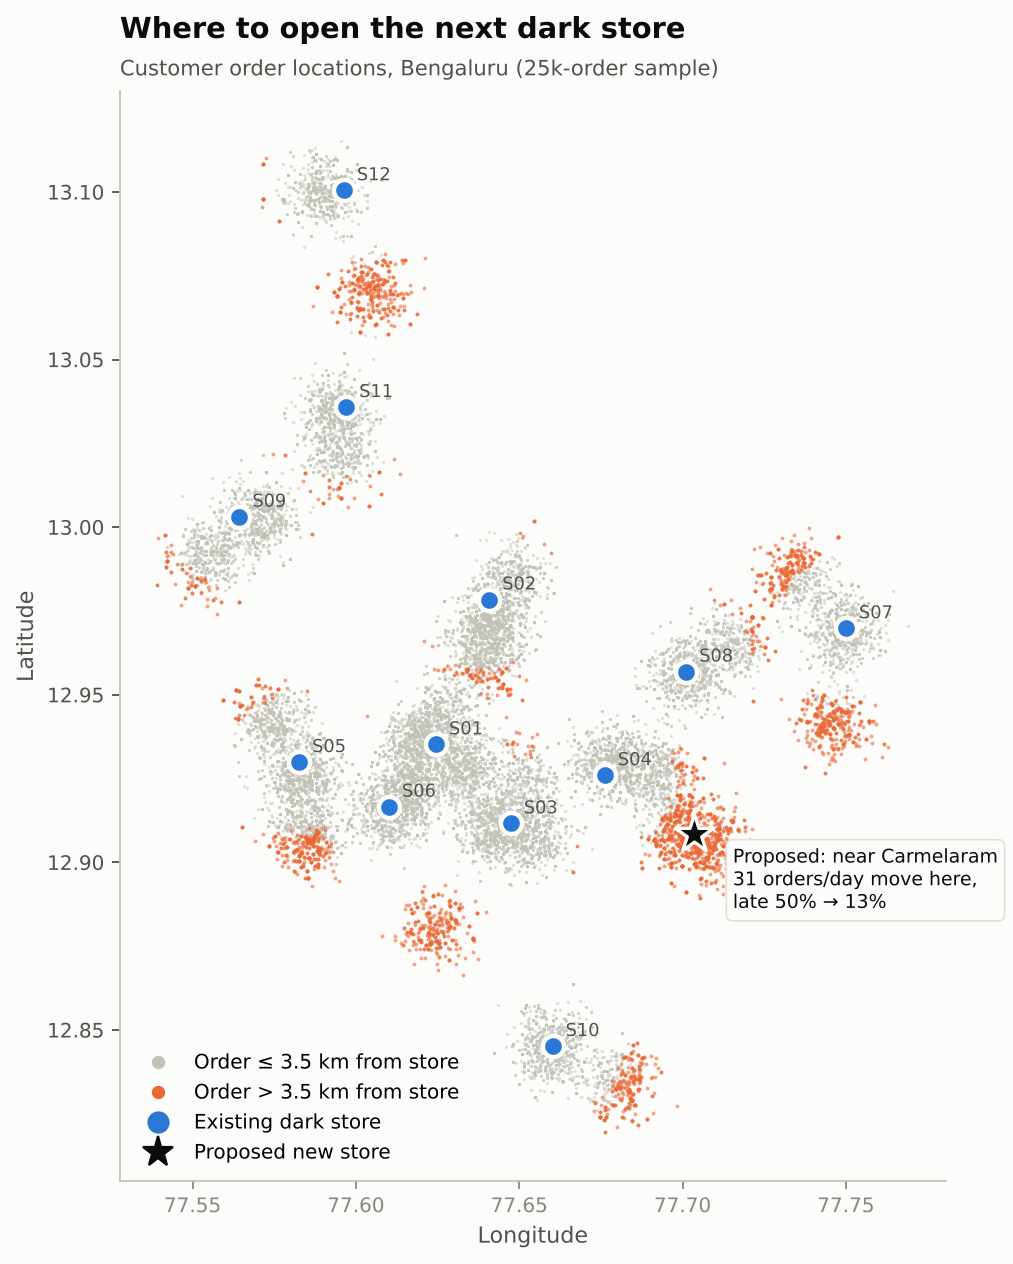

In [26]:
Image(FIG / "10_expansion_map.png", width=650)

## 10. Recommendations (each with a simulated impact)

In [27]:
s07, s03, s10, ns = (m[k] for k in ["whatif_staffing_S07", "whatif_staffing_S03", "whatif_picking_S10", "whatif_new_store_best"])
pd.DataFrame([
    ["Re-hire riders at HSR Layout (S03)", f"+{s03['extra_rider_hours_per_day']} rider-hrs/day", f"{s03['late_pct_now']}% -> {s03['late_pct_after_fix']}%"],
    ["Add rider shifts at Whitefield (S07)", f"+{s07['extra_rider_hours_per_day']} rider-hrs/day", f"{s07['late_pct_now']}% -> {s07['late_pct_after_fix']}%"],
    ["Fix picking at Electronic City (S10)", f"-{s10['excess_pick_min']} min per order", f"{s10['late_pct_now']}% -> {s10['late_pct_after_fix']}%"],
    [f"Open store near {ns['candidate_site_near']}", f"{ns['orders_reassigned_per_day']:.0f} orders/day move", f"{ns['late_pct_now']}% -> {ns['late_pct_new']}% (moved orders)"],
], columns=["Action", "Effort", "Late rate"])

,Action,Effort,Late rate
0,Re-hire riders at HSR Layout (S03),+23.0 rider-hrs/day,60.9% -> 12.6%
1,Add rider shifts at Whitefield (S07),+12.3 rider-hrs/day,39.6% -> 14.7%
2,Fix picking at Electronic City (S10),-1.98 min per order,43.2% -> 19.4%
3,Open store near Carmelaram,31 orders/day move,49.7% -> 12.7% (moved orders)


**Caveats.** The data is simulated, so the exact numbers illustrate the method rather than a real company. The what-if simulations hold everything else constant (e.g. a new store is assumed to pick and dispatch at today's network speed), and the retention comparison is observational - customers with late first orders may differ in other ways (they live further away, for example).